<a href="https://colab.research.google.com/github/AlfredaDhaifullah04/Pembelajaran_Mesin_2026/blob/main/TG9_JS11_Alfreda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#JOBSHEET 11 - Klasifikasi 2
## Support Vector Machine (SVM)
Pengenalan konsep dasar, optimal hyperplane, kernel trick, dan implementasi praktis klasifikasi menggunakan Scikit-Learn.

## Praktikum 1 - Klasifikasi SVM dengan Data Dummy Linier

In [12]:
# Langkah 1 - import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

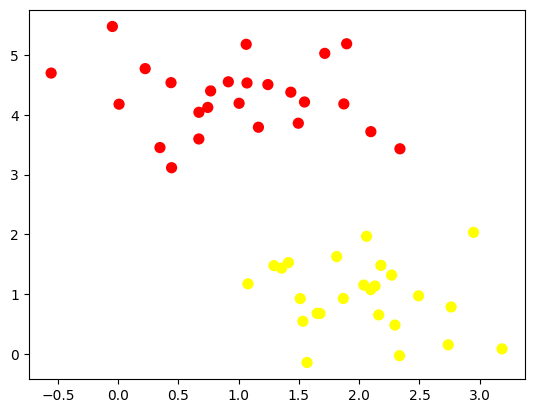

In [14]:
# Langkah 1 - Import Library

from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

(-1.0, 3.5)

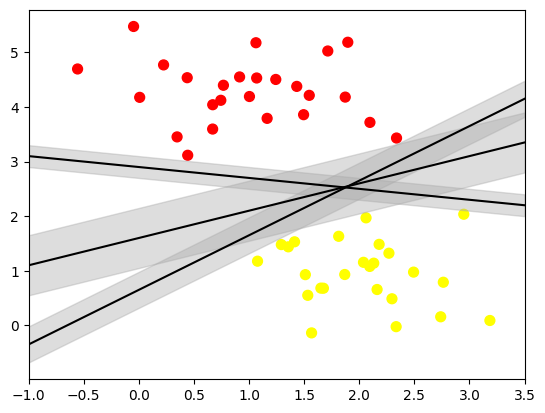

In [19]:
	xfit = np.linspace(-1, 3.5)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

	for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
	    yfit = m * xfit + b
	    plt.plot(xfit, yfit, '-k')
	    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
	                     color='#AAAAAA', alpha=0.4)

	plt.xlim(-1, 3.5)

In [21]:
	from sklearn.svm import SVC # "Support vector classifier"
	model = SVC(kernel='linear', C=1E10)
	model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

In [22]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

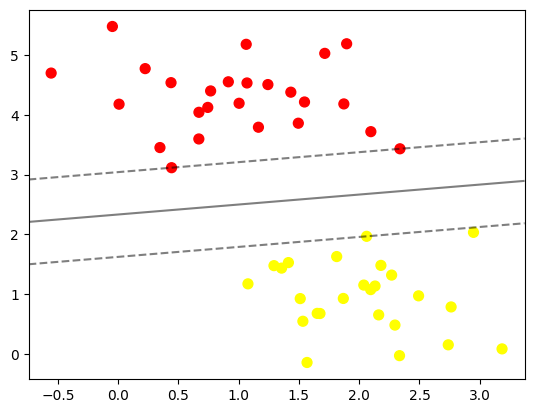

In [23]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(model)

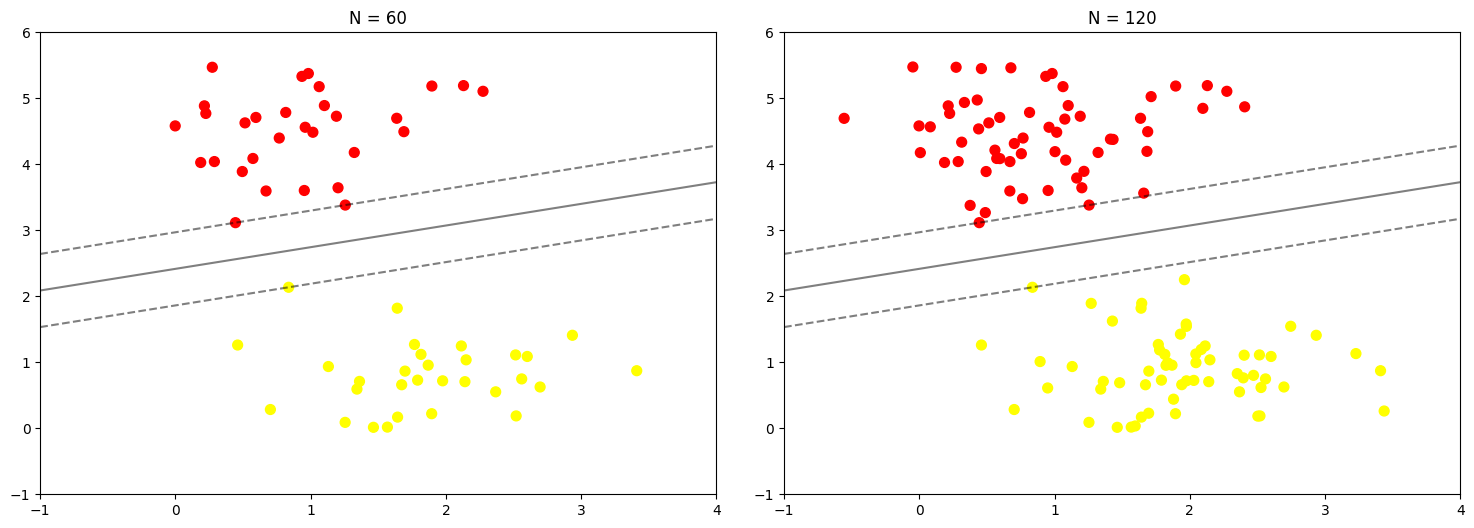

In [24]:
	def plot_svm(N=10, ax=None):
	    X, y = make_blobs(n_samples=200, centers=2,
	                      random_state=0, cluster_std=0.60)
	    X = X[:N]
	    y = y[:N]
	    model = SVC(kernel='linear', C=1E10)
	    model.fit(X, y)

	    ax = ax or plt.gca()
	    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    ax.set_xlim(-1, 4)
	    ax.set_ylim(-1, 6)
	    plot_svc_decision_function(model, ax)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
	for axi, N in zip(ax, [60, 120]):
	    plot_svm(N, axi)
	    axi.set_title('N = {0}'.format(N))

In [25]:
	# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model


	from ipywidgets import interact, fixed
	interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

##Praktikum 2 - Klasifikasi SVM dengan Data Dummy Non-Linier

In [26]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC

In [27]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

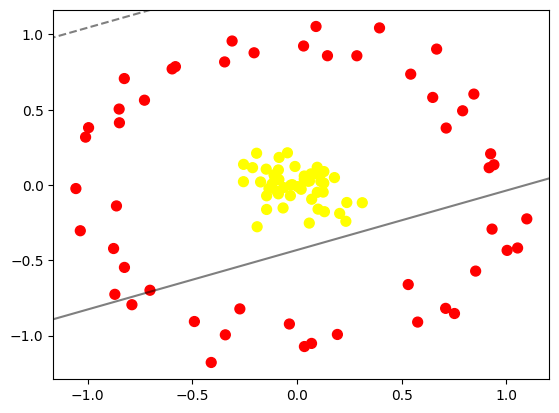

In [28]:
	# contoh data tidak terpisah secara linier
	from sklearn.datasets import make_circles
	X, y = make_circles(100, factor=.1, noise=.1)

	clf = SVC(kernel='linear').fit(X, y)

	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf, plot_support=False);

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 7.10538144e-01, -8.19319655e-01],
       [-8.23971163e-01, -5.47287803e-01],
       [-9.09990756e-03,  1.23281840e-01],
       [ 9.32332761e-01, -2.92715112e-01],
       [-3.45363937e-01,  8.17809197e-01],
       [ 9.25549506e-01,  2.07339713e-01],
       [-8.69767663e-01, -7.26067423e-01],
       [-8.24590802e-01,  7.07315915e-01],
       [-6.60934779e-02, -1.52393841e-01],
       [ 9.13102872e-02,  1.05324069e+00],
       [-7.28276844e-01,  5.63452864e-01],
       [ 5.90777294e-02, -2.52889477e-01],
       [-5.96066898e-01,  7.71459606e-01],
       [-1.06628506e-01,  5.91760409e-02],
       [ 6.98372742e-02, -1.05214161e+00],
       [-8.47948200e-01,  4.13552555e-01],
       [ 3.58582871e-02, -1.07287623e+00],
       [-9.95300544e-01,  3.81056244e-01],
       [ 2.03611794e-02, -2.81141075e-02],
       [ 2.04315092e-01, -1.88658729e-01],
       [-1.92569547e-01,  2.11152054e-01],
       [-5.80410386e-01,  7.86349439e-01],
       [ 1.45959495e-01,  8.58906350e-01],
       [ 8.51469049e-02,  7.53479835e-02],
       [ 8.45397717e-01,  6.04112780e-01],
       [-8.75846331e-01, -4.21738941e-01],
       [-2.54785364e-01,  1.37203035e-01],
       [ 1.28383379e-01,  1.29210705e-02],
       [ 1.25418304e-01, -4.68892708e-02],
       [ 7.13188770e-01,  3.78514769e-01],
       [-8.84738448e-02, -5.84492245e-02],
       [-1.05591853e+00, -2.34301495e-02],
       [ 6.73567712e-02,  7.41363672e-02],
       [-4.89805066e-01, -9.06781591e-01],
       [ 3.18560598e-02,  9.23547744e-01],
       [ 3.50144139e-02,  3.80611547e-02],
       [ 9.72752983e-02, -4.83358435e-02],
       [ 2.33887329e-01, -2.40834087e-01],
       [ 7.91741537e-01,  4.93145188e-01],
       [ 7.52747644e-01, -8.53508331e-01],
       [-8.60552907e-02,  3.59270845e-02],
       [ 3.99693356e-03, -1.07512439e-02],
       [ 1.79359209e-01,  4.93754872e-02],
       [ 8.53910946e-01, -5.71707942e-01],
       [-9.38375502e-02, -4.32883183e-02],
       [-8.62119008e-01, -1.38764233e-01],
       [-2.04607639e-01,  8.78454320e-01],
       [-2.72612558e-01, -8.22772937e-01],
       [ 5.24899824e-02,  2.51778152e-02],
       [-1.89991284e-01, -2.77206489e-01],
       [ 6.67539541e-01,  9.03005942e-01],
       [-1.44693937e-01, -7.14512403e-02],
       [-1.33550564e-01, -2.37490939e-02],
       [-1.00965035e+00,  3.18123224e-01],
       [-2.11934062e-01,  1.15382027e-01],
       [ 5.31785896e-01, -6.61065439e-01],
       [ 2.86373116e-01,  8.58622419e-01],
       [-7.88242884e-01, -7.95169032e-01],
       [-2.23019502e-02,  2.26535901e-03],
       [ 6.48882622e-01,  5.81931452e-01],
       [ 9.18420306e-01,  1.15064237e-01],
       [ 1.31453798e-01, -1.77093908e-01],
       [-2.55409817e-01,  2.22565282e-02],
       [-6.34872485e-02, -1.70257995e-02],
       [-3.59358293e-02, -9.23211944e-01],
       [ 1.09594429e-01,  6.61144646e-02],
       [-1.73527938e-01,  2.04945504e-02],
       [ 3.50942650e-02,  5.99450361e-02],
       [ 1.93412919e-01, -9.92651010e-01],
       [-2.96285699e-02, -1.06335810e-03],
       [-4.09428401e-01, -1.17878697e+00],
       [-1.18308531e-01,  7.30569819e-03],
       [-7.01955192e-01, -6.99018765e-01],
       [ 5.43721799e-01,  7.36504407e-01],
       [-4.52403406e-02,  2.14028564e-01],
       [ 3.12281818e-01, -1.17457668e-01],
       [-3.09619227e-01,  9.56651031e-01],
       [ 1.01032607e-01, -1.60235637e-01],
       [-3.11707398e-02, -7.07649419e-02],
       [-1.46691349e-01,  1.05420244e-01],
       [ 6.00670655e-02,  2.70600834e-02],
       [-8.85712050e-02,  1.00104322e-01],
       [ 1.05433150e+00, -4.18222686e-01],
       [-8.51120202e-02,  1.83297470e-01],
       [ 3.94701810e-01,  1.04377380e+00],
       [ 9.70012799e-02,  1.17960138e-01],
       [ 7.05323990e-02, -9.43010241e-02],
       [-1.44779808e-01, -1.62323306e-01],
       [ 1.09830406e+00, -2.24817100e-01],
       [ 1.28757699e-01,  8.95096014e-02],
       [ 2.38411056e-01, -1.16090314e-01],
       [-1.03488727e+00, -3.03693579e-01

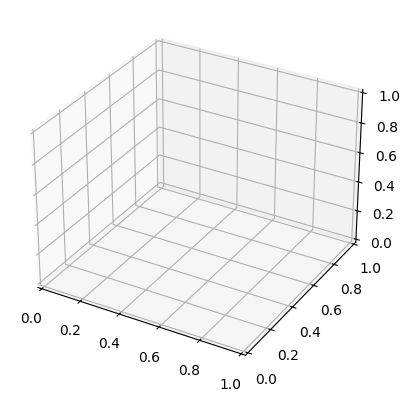

In [30]:
	from mpl_toolkits import mplot3d
	from ipywidgets import interact, fixed

	def plot_3D(elev=30, azim=30, X=X, y=y):
	    ax = plt.subplot(projection='3d')
	    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
	    ax.view_init(elev=elev, azim=azim)
	    ax.set_xlabel('x')
	    ax.set_ylabel('y')
	    ax.set_zlabel('r')

	interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
	         X=fixed(X), y=fixed(y))

In [31]:
	clf = SVC(kernel='rbf', C=1E6)
	clf.fit(X, y)

SVC(C=1000000.0)

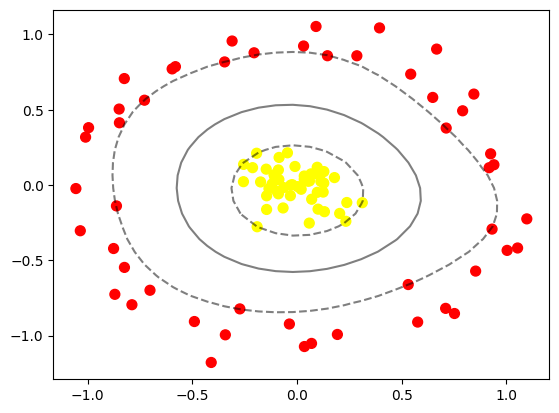

In [32]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf)
	plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
	            s=300, lw=1, facecolors='none')

##Praktikum 3 - SVM Data Overlapping

In [33]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC
	from sklearn.datasets import make_blobs

In [34]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

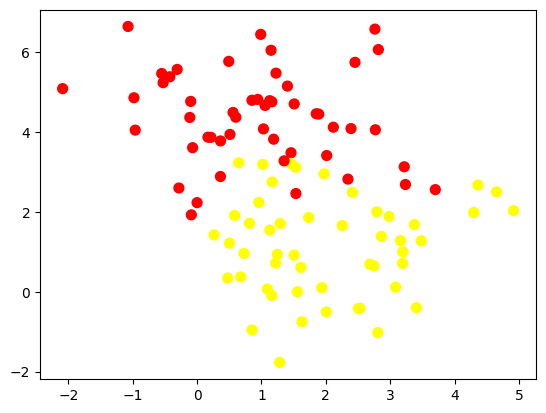

In [35]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=1.2)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

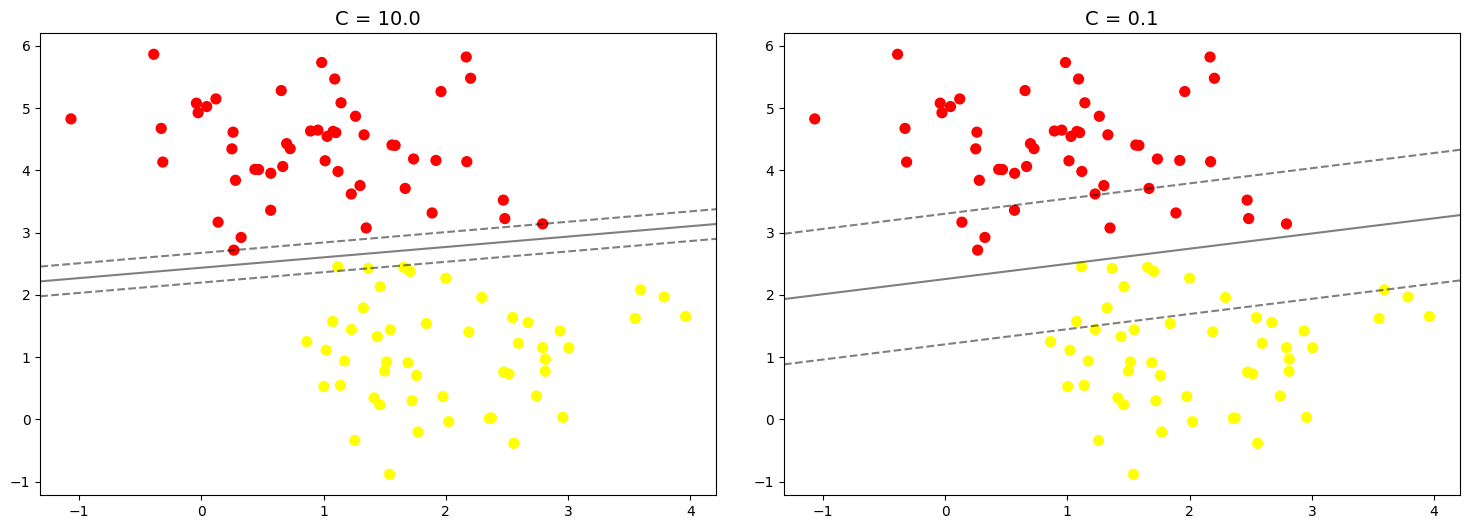

In [36]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=0.8)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

	for axi, C in zip(ax, [10.0, 0.1]):
	    model = SVC(kernel='linear', C=C).fit(X, y)
	    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    plot_svc_decision_function(model, axi)
	    axi.scatter(model.support_vectors_[:, 0],
	                model.support_vectors_[:, 1],
	                s=300, lw=1, facecolors='none');
	    axi.set_title('C = {0:.1f}'.format(C), size=14)

## Praktikum 4 - Klasifikasi Citra Wajah

In [37]:
	from sklearn.datasets import fetch_lfw_people
	faces = fetch_lfw_people(min_faces_per_person=60)
	print(faces.target_names)
	print(len(faces.target_names))
	print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


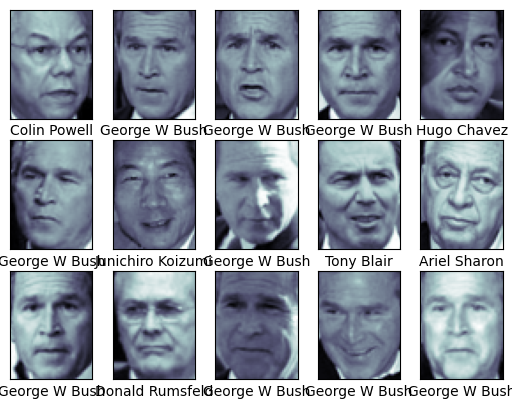

In [38]:
	# contoh wajah yang digunakan
	from matplotlib import pyplot as plt

	fig, ax = plt.subplots(3, 5)
	for i, axi in enumerate(ax.flat):
	    axi.imshow(faces.images[i], cmap='bone')
	    axi.set(xticks=[], yticks=[],
	            xlabel=faces.target_names[faces.target[i]])

In [39]:
	from sklearn.svm import SVC
	from sklearn.decomposition import PCA as RandomizedPCA
	from sklearn.pipeline import make_pipeline

	pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
	svc = SVC(kernel='rbf', class_weight='balanced')

	# Pipeline digunakan untuk melakukan proses secara bertahap dalam
	# 1 eksekusi fungsi secara langsung
	model = make_pipeline(pca, svc)

In [40]:
	# pemisahan data training dan data testing

	from sklearn.model_selection import train_test_split
	Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

In [41]:
	from sklearn.model_selection import GridSearchCV
	param_grid = {'svc__C': [1, 5, 10, 50],
	              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
	grid = GridSearchCV(model, param_grid)

	%time grid.fit(Xtrain, ytrain)
	print(grid.best_params_)
	print(grid.best_score_)

CPU times: user 2min 20s, sys: 180 ms, total: 2min 21s
Wall time: 1min 31s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


In [42]:
	model = grid.best_estimator_
	yfit = model.predict(Xtest)

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

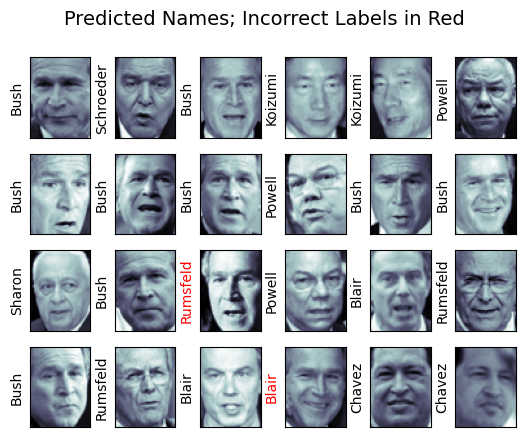

In [43]:
	# hasil label pada data testing

	fig, ax = plt.subplots(4, 6)
	for i, axi in enumerate(ax.flat):
	    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
	    axi.set(xticks=[], yticks=[])
	    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
	                   color='black' if yfit[i] == ytest[i] else 'red')
	fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

In [44]:
	from sklearn.metrics import classification_report
	print(classification_report(ytest, yfit,
	                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Text(113.92222222222219, 0.5, 'predicted label')

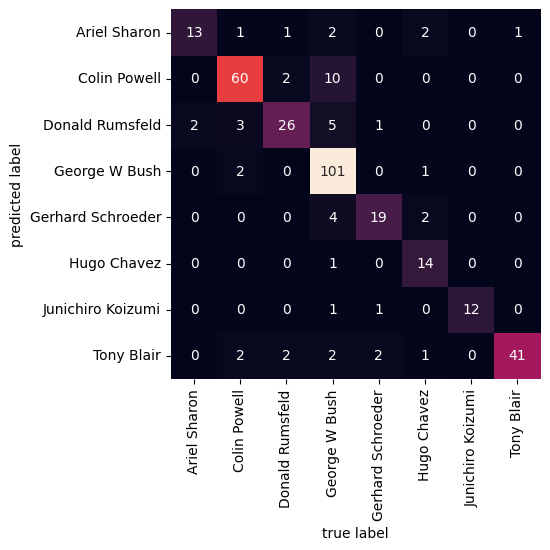

In [45]:
	# bentuk confusion matrix
	from sklearn.metrics import confusion_matrix
	import seaborn as sns

	mat = confusion_matrix(ytest, yfit)
	sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
	            xticklabels=faces.target_names,
	            yticklabels=faces.target_names)
	plt.xlabel('true label')
	plt.ylabel('predicted label')

## Praktikum 5 - Klasifikasi Citra Siang dan Malang

In [46]:
	# Import Required Libraries
	from pathlib import Path
	import matplotlib.image as mpimg
	import matplotlib.pyplot as plt
	import cv2
	import random
	import numpy as np
	import pandas as pd

In [47]:
	# Image directories
	train_dir = "images/training/"
	test_dir = "images/test/"

In [54]:
	def load_dataset(img_dir):
	    p = Path(img_dir)
	    dirs = p.glob('*')

	    img_list = []

	    for dir in dirs:
	        label = str(dir).split('/')[-1]
	        for file in dir.glob('*.jpg'):
	            img = mpimg.imread(file)

	            if not img is None:
	                img_list.append((img, label))

	    return img_list

In [55]:
	# Load training data
	train_img = load_dataset(train_dir)

In [57]:
# Ekstrak dataset jika belum diekstrak
import zipfile
import os

if not os.path.exists('images'):
    with zipfile.ZipFile('images.zip', 'r') as zip_ref:
        zip_ref.extractall('.')

# Load ulang dataset
train_img = load_dataset(train_dir)

# Tampilkan data pertama
train_img[0]

(array([[[97, 54, 71],
         [59, 16, 33],
         [94, 51, 70],
         ...,
         [71, 51, 76],
         [62, 43, 71],
         [43, 27, 54]],
 
        [[85, 42, 59],
         [42,  0, 16],
         [83, 40, 57],
         ...,
         [32,  9, 38],
         [24,  5, 35],
         [43, 27, 56]],
 
        [[38,  0, 11],
         [94, 53, 67],
         [73, 32, 46],
         ...,
         [41, 15, 52],
         [50, 28, 66],
         [46, 26, 63]],
 
        ...,
 
        [[34,  3, 21],
         [31,  0, 15],
         [38,  6, 17],
         ...,
         [37,  9,  5],
         [43, 15, 11],
         [37,  9,  5]],
 
        [[56, 27, 32],
         [37,  8, 10],
         [44, 14, 12],
         ...,
         [37,  8,  0],
         [54, 25, 17],
         [26,  0,  0]],
 
        [[62, 38, 28],
         [47, 23, 11],
         [67, 41, 26],
         ...,
         [56, 27, 13],
         [76, 47, 33],
         [39, 11,  0]]], dtype=uint8),
 'night')

In [61]:
	# Random size checking
	pick_random = np.random.randint(0, len(train_img))

	# Check img size
	print(f'Image {pick_random}')
	print(train_img[pick_random][0].shape)

Image 141
(737, 1024, 3)


In [62]:
	# Function to Visualize
	def random_img_viz(img_list):
	    rand_num = np.random.randint(0, len(img_list))

	    img = img_list[rand_num][0]
	    label = img_list[rand_num][1]
	    label_str = 'day' if label == 1 else 'night'

	    plt.imshow(img)
	    print(f'Shape\t: {img.shape}')
	    print(f'Label\t: {label}')

Shape	: (458, 800, 3)
Label	: night


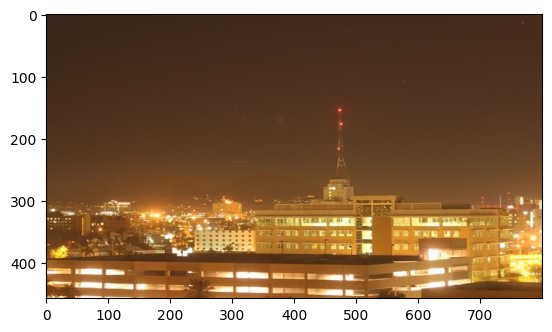

In [65]:
random_img_viz(train_img)

In [66]:
	def standarized_input(image):
	    # resize to w: 1100, h:600
	    std_img = cv2.resize(image, (1100,600))

	    return std_img

In [67]:
	def label_encoder(label):
	    # Encode the label
	    # day as 1; night as 0
	    num_val = 0

	    if(label == 'day'):
	        num_val = 1

	    return num_val

In [68]:
	def preprocess(img_list):
	    std_img_list = []

	    for item in img_list:
	        image = item[0]
	        label = item[1]

	        # Standarized the image
	        std_img = standarized_input(image)

	        # Create the label
	        img_label = label_encoder(label)

	        std_img_list.append((std_img, img_label))

	    return std_img_list

In [69]:
train_std_img_list = preprocess(train_img)

In [74]:
	# Random size checking
	pick_random = np.random.randint(0, len(train_std_img_list))

	# Check img size
	print(f'Image {pick_random}')
	print(train_std_img_list[pick_random][0].shape)

Image 76
(600, 1100, 3)


In [75]:
	# Get feature based on average brightness using HSV colorspace
	def avg_brightness(image):
	    # Convert image to HSV
	    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

	    # Calculate the avg of brightness
	    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rb value which is the V channel
	    area = image.shape[0] * image.shape[1]
	    avg = sum_brightness / area

	    return avg

Image 203
Avg Brighness: 189.6267


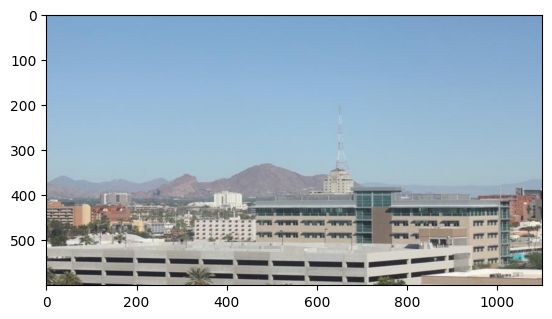

In [76]:
	# Check on random image
	rand_img = np.random.randint(0, len(train_std_img_list))

	feature_img = train_std_img_list[rand_img][0]

	avg_img = avg_brightness(feature_img)

	print(f'Image {rand_img}')
	print(f'Avg Brighness: {avg_img:.4f}')
	plt.imshow(feature_img)

In [77]:
	def predict_label(img, threshold):
	    # Computer average brightness
	    avg = avg_brightness(img)
	    pred = 0

	    # Predict the label based on user defined threshold
	    if avg > threshold:
	        pred = 1

	    return pred

Image 170
Actual label: 1
Predicted label: 1


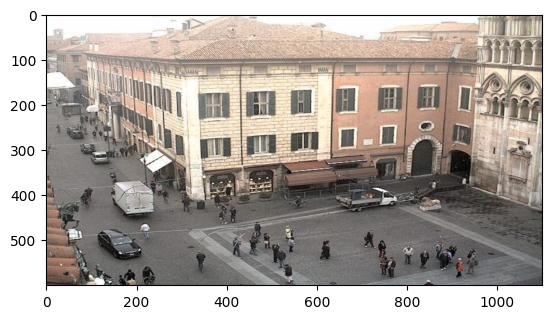

In [78]:
	# Test the classifier on train data
	rand_img = np.random.randint(0, len(train_std_img_list))

	pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

	# Evaluate
	print(f'Image {rand_img}')
	print(f'Actual label: {train_std_img_list[rand_img][1]}')
	print(f'Predicted label: {pred}')
	plt.imshow(train_std_img_list[rand_img][0])

In [79]:
	def evaluate(img_list, threshold):
	    miss_labels = []

	    for file in img_list:
	        # Get the ground truth / correct label
	        img = file[0]
	        label = file[1]

	        # Get prediction
	        pred_label = predict_label(img, threshold)

	        # Compare ground truth and pred
	        if pred_label != label:
	            miss_labels.append((img, pred_label, label))

	    total_img = len(img_list)
	    corr_pred = total_img - len(miss_labels)
	    accuracy = corr_pred / total_img

	    print(f'Accuracy: {accuracy:.4f}')

In [81]:
	# Evaluate on train data
	evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [82]:
	# Evaluate on test data

	# Load test data
	test_img = load_dataset(test_dir)

	# Preprocess
	test_std_img_list = preprocess(test_img)

	# Predict
	evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


In [83]:
	# Create function to extract feature for every images and stored in tabular data
	# Stored in Pandas dataframe
	def extract_avg_bright_feature(img_list):
	    avg_list = []
	    labels = []

	    for img in img_list:
	        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
	        img_label = img[1] # Get the image label

	        avg_list.append(img_avg)
	        labels.append(img_label)

	    # Stack data in columcular way
	    data = np.column_stack((avg_list, labels))
	    # Create a Pandas dataframe
	    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

	    return df

In [84]:
	# Extract feature on train data
	train_avg_img = extract_avg_bright_feature(train_std_img_list)
	print(f'Shape: {train_avg_img.shape}')
	train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,101.579750,0.0
1,93.118320,0.0
2,99.679486,0.0
3,54.999277,0.0
4,119.603174,0.0


In [85]:
	# Do the same thing on test data
	test_avg_img = extract_avg_bright_feature(test_std_img_list)
	print(f'Shape: {test_avg_img.shape}')
	test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,41.211485,0.0
1,19.274156,0.0
2,86.462873,0.0
3,98.235594,0.0
4,116.502630,0.0


In [86]:
	# import requied library
	from sklearn.svm import SVC

	# Split data and label
	X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
	y_train = train_avg_img.iloc[:,1]
	X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
	y_test = test_avg_img.iloc[:,1]

	model = SVC()
	model.fit(X_train, y_train)

SVC()

In [87]:
	from sklearn.metrics import accuracy_score

	# Make a prediction on train data
	y_train_pred = model.predict(X_train)

	# Get the accuracy on train data
	acc_train = accuracy_score(y_train, y_train_pred)

	# Make a prediction on test data
	y_test_pred = model.predict(X_test)

	# Get the accuracy on test data
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print Eval Result
	print(f'Accuracy on train: {acc_train}')
	print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


## Tugas Praktikum

Soal 1

In [88]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 1. Load Data
df = pd.read_csv('voice.csv')

# 2. Preprocessing Feature & Label
X = df.drop('label', axis=1)
y = df['label']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 3. Pengujian Model
splits = [0.3, 0.2]  # 70:30 dan 80:20
split_labels = ['70:30', '80:20']
kernels = ['linear', 'poly', 'rbf']

results = []

for test_size, split_name in zip(splits, split_labels):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_encoded, test_size=test_size, random_state=42, stratify=y_encoded
    )

    # Feature Scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    for kernel in kernels:
        model = SVC(kernel=kernel, random_state=42)
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)

        acc = accuracy_score(y_test, y_pred)
        results.append({
            'Rasio Split': split_name,
            'Kernel': kernel,
            'Akurasi': f"{acc:.4f}"
        })

# 4. Tampilkan Tabel
df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

Rasio Split Kernel Akurasi
      70:30 linear  0.9790
      70:30   poly  0.9600
      70:30    rbf  0.9832
      80:20 linear  0.9748
      80:20   poly  0.9558
      80:20    rbf  0.9826


Soal 2

In [89]:
import os
import cv2
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# 1. Fungsi Ekstraksi Fitur Histogram Warna
def extract_color_histogram(image_path, bins=(8, 8, 8)):
    image = cv2.imread(image_path)
    if image is None:
        return None
    # Konversi gambar ke HSV (atau RGB)
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    # Hitung 3D histogram
    hist = cv2.calcHist([hsv], [0, 1, 2], None, bins, [0, 180, 0, 256, 0, 256])
    # Normalisasi histogram
    cv2.normalize(hist, hist)
    return hist.flatten()

# 2. Load Dataset dari Folder (Sesuaikan path folder Anda)
# Struktur folder:
# dataset/
# ├── siang/
# └── malam/

def load_dataset(base_path):
    X, y = [], []
    categories = ['siang', 'malam']

    for category in categories:
        folder_path = os.path.join(base_path, category)
        label = 0 if category == 'siang' else 1

        if not os.path.exists(folder_path):
            continue

        for file in os.listdir(folder_path):
            img_path = os.path.join(folder_path, file)
            features = extract_color_histogram(img_path)
            if features is not None:
                X.append(features)
                y.append(label)

    return np.array(X), np.array(y)

# Ganti dengan path folder gambar Anda di Google Colab
DATASET_PATH = 'dataset_siang_malam'

# X, y = load_dataset(DATASET_PATH)

# --- Contoh Eksekusi & Hyperparameter Tuning ---
# (Pastikan X dan y sudah terisi dari folder gambar Anda)

if 'X' in locals() and len(X) > 0:
    # Split Data 80:20
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Scaling Fitur
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Hyperparameter Tuning untuk Kernel RBF (C dan gamma)
    param_grid = {
        'C': [0.1, 1, 10, 100],
        'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
    }

    grid_search = GridSearchCV(
        SVC(kernel='rbf', random_state=42),
        param_grid,
        cv=5,
        scoring='accuracy'
    )

    grid_search.fit(X_train_scaled, y_train)

    # Evaluasi Model Terbaik
    best_model = grid_search.best_estimator_
    y_pred = best_model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)

    print("=== Hasil Tuning & Evaluasi ===")
    print(f"Hyperparameter Terbaik: {grid_search.best_params_}")
    print(f"Akurasi Test Set (80:20): {acc * 100:.2f}%")
    print("\nLaporan Klasifikasi Detail:")
    print(classification_report(y_test, y_pred, target_names=['Siang', 'Malam']))

=== Hasil Tuning & Evaluasi ===
Hyperparameter Terbaik: {'C': 100, 'gamma': 0.1}
Akurasi Test Set (80:20): 98.58%

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

       Siang       0.98      0.99      0.99       317
       Malam       0.99      0.98      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634

